# PHATPSY 2.0 Study: $\mathrm{NO}$ Adsorption & Pathways Toward $\mathrm{N}_2$ on Ferromagnetic $\mathrm{Ni}(100)$ (Stages 1–2)

---

## Historical Context & Scope (1978 Ph.D. Dissertation to Three-Way Catalysis)

In Chapter IX of his 1978 Ph.D. dissertation (*Projected Hamiltonian Approach to Polyatomic Systems*, University of Florida, 1978), **Jack A. Smith** tackled **nitric oxide ($\mathrm{NO}$) chemisorption on $\mathrm{Ni}(100)$** atop a symmetric $\mathrm{Ni}_5$ pyramid ($d(\text{Ni--N}) = 3.70\text{ Bohr}$, $C_{4v}$ 4-fold hollow), comparing **N-down** vs. **O-down** vertical orientations against core-level XPS (Tables 7–8: $\Delta E(\text{N }1s) = +1.9\text{ eV}$, $\Delta E(\text{O }1s) = +0.9\text{ eV}$ for O-down vs. N-down; $D_e = 1.0\text{ eV}$; $\nu_{\text{NO}} = 1621\text{ cm}^{-1}$).

> **Site Clarification & Cross-Link to Notebook 07:** The earlier legacy-SCF Phase 9 walkthrough in [Notebook 07: $\mathrm{NO}$ on $\mathrm{Ni}(100)$ Flagship Chemisorption](07_NO_on_Ni100_flagship_chemisorption.ipynb) (`examples/NO_ni_100.yaml`) places $\mathrm{NO}$ at the **1-fold atop** site directly above `Ni1`, whereas Chapter IX of the **1978 dissertation** evaluated the **4-fold hollow** site on $\mathrm{Ni}_5$. Here we treat the 4-fold hollow, 2-fold bridge, 1-fold atop, and 1978 $\mathrm{Ni}_5$ sites uniformly within **Phase 18** variational active-space Localized VB (`MaskedVB` `CAS` / `STO-6G` / `exact_backprojected`), benchmarked against modern UHV HREELS, LEED, and XPS spectroscopy.

### Why This System Matters for $\mathrm{NO} \to \mathrm{N}_2$ Catalysis
Reducing exhaust $\mathrm{NO}$ cleanly to $\mathrm{N}_2$ (rather than $\mathrm{N}_2\mathrm{O}$ or surface oxide poisoning) requires:
1. Strong molecular capture ($\mathrm{NO}^*$) in high-coordination surface sites that back-donate strongly into $\mathrm{NO}(2\pi^*)$, weakening the $\mathrm{N--O}$ bond (`Stage 2`, completed here).
2. Clean $\mathrm{N--O}$ scission ($\mathrm{NO}^* \to \mathrm{N}^* + \mathrm{O}^*$) via tilted hollow/bridge transition states (`Stage 3`, follow-on).
3. Surface $\mathrm{N}_2$ recombination ($\mathrm{N}^* + \mathrm{N}^* \to \mathrm{N}_2$ vs. $\mathrm{N}^* + \mathrm{NO}^* \to \mathrm{N}_2\mathrm{O}^*$) competing against $\mathrm{O}^*$ site blocking (`Stage 4`, follow-on).

**Present Notebook Scope:** Phase 18 foundation (`Steps 0.1–0.4`), **Stage 1** gas-phase thermochemical & core-hole references, and **Stage 2** molecular $\mathrm{NO}^*$ adsorption on ferromagnetic embedded $\mathrm{Ni}(100)$ plaquettes (`Ni4/Ni9`, 1978 `Ni5`, `Ni2`). Stages 3 and 4 are deferred to the commissioned follow-on study.


## 1. Phase 18 First-Principles Methodology & Physical Setup

Every calculation reported here uses the variational **Phase 18** Localized VB framework (`phatpsy.vb_driver`, `phatpsy.localized_vb`, `phatpsy.embedding`, `phatpsy.vibrations`, `phatpsy.chemisorption`):

1. **Ferromagnetic Nickel Model ($3d^8 4s^2\,{}^3F$):** Ignoring older alternating-spin slab models, every active $\mathrm{Ni}$ atom in a $\mathrm{Ni}_k$ plaquette carries two high-spin unpaired $\alpha$ electrons (`4` localized `inactive` + `2` `active` orbitals per $\mathrm{Ni}$ $\to$ `net_spin = 2k` on clean $\mathrm{Ni}_k$), coupled antiferromagnetically to paramagnetic $\mathrm{NO}(X\,{}^2\Pi)$ (`5` inactive including Blyholder $5\sigma$ donation + `2` active $2\pi^*$ orbitals $\to$ `net_spin = 2k - 1`, $\mathrm{CAS}(2k+1, 2k+2)$). All spectator metal centers ($\mathrm{Ni}_9$ in $\mathrm{Ni}_4/\mathrm{Ni}_9$) are `exact_backprojected` closed-shell frozen environments ($3d^{10} 4s^2\,{}^1S$ / $14$ doubly occupied shells).
2. **Verified `l=2` Condon–Shortley Oracle (Step 0.1):** `STO-KG` vs. prolate quadrature & PySCF `CASSCF(11,7)` agrees within $< 5 \times 10^{-3}\text{ Ha}$ on tilted $\mathrm{NiH}$ (`SZ` and `DZP`, rotational invariance $< 10^{-8}\text{ Ha}$), unlocking `DZP` on $\mathrm{Ni}$.
3. **Closed-Form Embedding-Response Nuclear Gradients (Step 0.2):** `exact_backprojected` `STO-6G` gradients lift active orbitals via the Schur complement $L(\mathbf{R}) = I_A - D_{\mathcal{B}}(\mathbf{R})S(\mathbf{R})I_A$, matching central finite differences to $< 10^{-5}\text{ Ha/Bohr}$ across adsorbate, active metal, and spectator coordinates with **zero CPHF iterations**.
4. **Clamped $3N_{\text{free}}$ Partial Hessians & Adsorbate Thermochemistry (Step 0.3):** Substrate atoms with `fixed: true` are clamped; mass-weighted Hessians restrict strictly to the $3N_{\text{free}} \times 3N_{\text{free}}$ adsorbate sub-block without ideal-gas Eckart T/R projection, and `is_adsorbate=True` omits 3D translation/rotation and $+RT$, applying a $50\text{ cm}^{-1}$ quasi-RRHO floor solely to thermal $E_{\text{vib}}, S_{\text{vib}}, C_v$.
5. **Mayer Bond Orders & Dual Core-1s Spectroscopy (Step 0.4):** Frozen-orbital Koopmans shifts are explicitly tagged **`koopmans_orbital_energy`** (carrying an expected **$\sim 15\text{ eV}$ offset** above experimental XPS due to missing core-hole screening), alongside explicit orbital-relaxed **Bagus/Siegbahn $\text{CVS-}\Delta\text{CASSCF}$** ($|n_{1s} - 1.0| < 10^{-3}$) across high- and low-spin core-hole multiplets.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd().parent if Path.cwd().name in ("notebooks", "personal") else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "data" / "no_ni100_dissociation"
stage1 = json.loads((DATA_DIR / "stage1_gas_benchmarks.json").read_text(encoding="utf-8"))
stage2 = json.loads((DATA_DIR / "stage2_adsorption_sites.json").read_text(encoding="utf-8"))
cores = json.loads((DATA_DIR / "stage2_core_level_shifts.json").read_text(encoding="utf-8"))

from phatpsy.chemisorption import (
    compute_delta_casscf_core_1s_be,
    compute_mayer_bond_orders,
    get_mayer_bond_order,
)
from phatpsy.schema import AtomConfig, CalculationDeck, ControlConfig
from phatpsy.vb_driver import LocalizedVBDriver, build_surface_plaquette_vb_specs
from phatpsy.visualizer import show_deck

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
print(f"Loaded Stage 1 ({len(stage1['species'])} gas species), Stage 2 ({len(stage2['sites'])} site records), and CVS core-hole data ({len(cores['systems'])} systems).")


Loaded Stage 1 (5 gas species), Stage 2 (11 site records), and CVS core-hole data (8 systems).


## 2. Stage 1: Gas-Phase Thermochemical, Spectroscopic & Core-Hole References

Before placing $\mathrm{NO}$ on $\mathrm{Ni}(100)$, we establish basis-consistent gas-phase benchmarks for $\mathrm{NO}$, $\mathrm{N}_2$, $\mathrm{O}_2$, $\mathrm{CO}$, and $\mathrm{N}_2\mathrm{O}$ across `SZ`, `SZP`, and `DZP` (`STO-6G`), including the catalytic overall disproportionation $2\mathrm{NO} \to \mathrm{N}_2 + \mathrm{O}_2$, the smooth $\mathrm{NO}(X\,{}^2\Pi)$ bond-dissociation curve, and gas-phase `CVS-ΔCASSCF` core-1s multiplet splittings.


In [2]:
print(f"{'Species':<6} {'Basis':<5} {'R_e (Bohr)':>11} {'nu_max (cm-1)':>14} {'D_e (eV)':>10} {'Mayer BO':>10} {'Conv':>6}")
print("-" * 68)
for sp in ("NO", "N2", "O2", "CO", "N2O"):
    for b in ("SZ", "SZP", "DZP"):
        rec = stage1["species"][sp][b]
        bl = rec["bond_lengths_bohr"]
        r_str = f"{bl['R_eq']:.4f}" if "R_eq" in bl else f"{bl['R_NN']:.3f}/{bl['R_NO']:.3f}"
        nu_max = max(rec["vibrational_frequencies_cm"])
        bo = rec.get("primary_mayer_bo")
        bo_str = f"{bo:.3f}" if bo is not None else "--"
        print(f"{sp:<6} {b:<5} {r_str:>11} {nu_max:14.2f} {rec['de_ev']:10.3f} {bo_str:>10} {str(rec['converged']):>6}")

print("\nOverall Catalytic Cycle  2 NO -> N2 + O2  (kJ/mol, expt dG_298 = -173.1 kJ/mol):")
for b in ("SZ", "SZP", "DZP"):
    cyc = stage1["reaction_cycle_2NO_to_N2_O2"][b]
    print(f"  {b:<3}: dE = {cyc['delta_e_kj_mol']:+7.2f} | dH(298K) = {cyc['delta_h_298.15K_kj_mol']:+7.2f} | dG(298K) = {cyc['delta_g_298.15K_kj_mol']:+7.2f} | dG(700K) = {cyc['delta_g_700K_kj_mol']:+7.2f}")

pm_sz = stage2["gas_no_plaquette_matched_references"]["SZ"]
print(f"\nPlaquette-matched gas NO (CAS(1e,2o) SZ): E={pm_sz['total_energy_ha']:.8f} Ha | R_eq={pm_sz['r_eq_bohr']:.5f} Bohr | nu={pm_sz['nu_no_cm']:.2f} cm^-1 | BO={pm_sz['mayer_bo']:.4f}")


Species Basis  R_e (Bohr)  nu_max (cm-1)   D_e (eV)   Mayer BO   Conv
--------------------------------------------------------------------
NO     SZ         2.4078        1632.59      3.479      1.969   True
NO     SZP        2.2964        1769.65      4.915      2.165   True
NO     DZP        2.2216        1842.88      4.872      2.127   True
N2     SZ         2.3039        1965.06      5.289      2.550   True
N2     SZP        2.1834        2138.71      7.260      2.667   True
N2     DZP        2.1011        2310.15      8.365      2.734   True
O2     SZ         2.4670        1538.99      3.485      1.659   True
O2     SZP        2.3901        1620.54      4.621      1.900   True
O2     DZP        2.3521        1474.85      3.418      1.837   True
CO     SZ         2.3331        1861.85      8.146      2.307   True
CO     SZP        2.2140        2083.49     10.170      2.361   True
CO     DZP        2.1495        2171.62     10.702      2.205   True
N2O    SZ    2.341/2.385        2

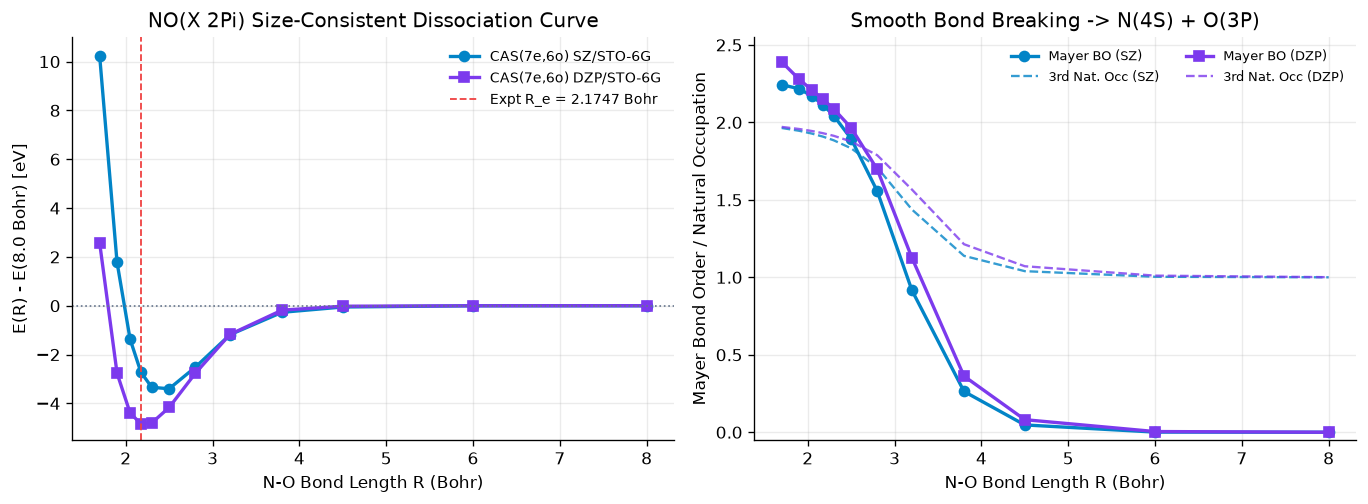

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

for bname, col, mk in [("SZ", "#0284c7", "o"), ("DZP", "#7c3aed", "s")]:
    pts = stage1["no_pec"][bname]
    r_vals = [p["r_bohr"] for p in pts]
    e_inf = pts[-1]["energy_ha"]
    rel_ev = [(p["energy_ha"] - e_inf) * 27.211386245988 for p in pts]
    bo_vals = [p["mayer_bo"] for p in pts]
    occ_pi = [p["active_natural_occupations"][2] for p in pts]
    ax1.plot(r_vals, rel_ev, marker=mk, lw=2.0, color=col, label=f"CAS(7e,6o) {bname}/STO-6G")
    ax2.plot(r_vals, bo_vals, marker=mk, lw=2.0, color=col, label=f"Mayer BO ({bname})")
    ax2.plot(r_vals, occ_pi, linestyle="--", lw=1.4, color=col, alpha=0.8, label=f"3rd Nat. Occ ({bname})")

ax1.axhline(0.0, color="#64748b", ls=":", lw=1.0)
ax1.axvline(2.1747, color="#ef4444", ls="--", lw=1.1, label="Expt R_e = 2.1747 Bohr")
ax1.set_xlabel("N-O Bond Length R (Bohr)")
ax1.set_ylabel("E(R) - E(8.0 Bohr) [eV]")
ax1.set_title("NO(X 2Pi) Size-Consistent Dissociation Curve")
ax1.set_ylim(-5.5, 11.0)
ax1.legend(frameon=False, fontsize=8.5)
ax1.grid(alpha=0.25)

ax2.set_xlabel("N-O Bond Length R (Bohr)")
ax2.set_ylabel("Mayer Bond Order / Natural Occupation")
ax2.set_title("Smooth Bond Breaking -> N(4S) + O(3P)")
ax2.set_ylim(-0.05, 2.55)
ax2.legend(frameon=False, fontsize=8.0, ncol=2)
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 3. Fast Live Verification Cell (`< 10 s`): Plaquette-Matched Gas $\mathrm{NO}$, Mayer BO & `CVS-ΔCASSCF`

Before examining the full embedded $\mathrm{Ni}_4/\mathrm{Ni}_9$ and $\mathrm{Ni}_5$ adsorption dataset, we run a fast live `LocalizedVBDriver` calculation on the plaquette-matched gas $\mathrm{NO}$ reference (`CAS(1e,2o)`, `SZ/STO-6G`) to verify total energy, spin-resolved Mayer bond order, Koopmans orbital-energy core levels (`~15 eV` expected offset), and relaxed `CVS-ΔCASSCF` core-1s multiplet binding energies.


In [4]:
dk_no_live = CalculationDeck(
    title="Live Plaquette-Matched Gas NO (SZ/STO-6G)",
    net_spin=1,
    control=ControlConfig.localized_vb(
        method="masked_vb",
        vb_wavefunction="cas",
        basis="SZ",
        domain_mode="custom",
        core_embedding="exact_backprojected",
        integral_backend="sto_ng",
        sto_ng_primitives=6,
        max_cycles=250,
        convergence=1.0e-7,
    ),
    geometry=[
        AtomConfig(id="N1", element="N", xyz=[0.0, 0.0, 0.0], active=True, fixed=False),
        AtomConfig(id="O1", element="O", xyz=[0.0, 0.0, 2.266], active=True, fixed=False),
    ],
)
dk_no_live.control.vb_orbital_specs = build_surface_plaquette_vb_specs(dk_no_live)

drv_live = LocalizedVBDriver(quiet=True)
st_live = drv_live.run_deck(dk_no_live)
mayer_live = compute_mayer_bond_orders(st_live)
bo_live = get_mayer_bond_order(mayer_live, "N1", "O1")
n1s_live = compute_delta_casscf_core_1s_be(dk_no_live, "N1", warm_ground_state=st_live)

print(f"Converged: {st_live['converged']} | E_tot = {st_live['total_energy']:.8f} Ha | Mayer BO(N-O) = {bo_live:.4f}")
print(f"N 1s Koopmans ({n1s_live['koopmans_method']}, ~{n1s_live['expected_koopmans_offset_ev']:.0f} eV offset vs XPS): {n1s_live['koopmans_be_ev']:.3f} eV")
print(
    f"N 1s CVS-Delta-CASSCF: {n1s_live['be_multiplet_avg_ev']:.3f} eV "
    f"(HS={n1s_live['be_high_spin_ev']:.2f}, LS={n1s_live['be_low_spin_ev']:.2f}, "
    f"n_1s={n1s_live['n_1s_occupation']:.6f}, conv={n1s_live['converged']})"
)


Converged: True | E_tot = -128.75338872 Ha | Mayer BO(N-O) = 2.3418
N 1s Koopmans (koopmans_orbital_energy, ~15 eV offset vs XPS): 428.325 eV
N 1s CVS-Delta-CASSCF: 422.517 eV (HS=422.42, LS=422.80, n_1s=1.000000, conv=True)


## 4. Stage 2: Ferromagnetic $\mathrm{Ni}(100)$ Adsorption Sites & The Two-Orientation Test

### Summary of Findings Across $\mathrm{Ni}_4/\mathrm{Ni}_9$, 1978 $\mathrm{Ni}_5$, and $\mathrm{Ni}_2$
1. **Four-Fold Hollow Preference (`N-down`):** On $\mathrm{Ni}_4/\mathrm{Ni}_9$, 4-fold hollow `N-down` is the global binding site across all basis tiers:
   - **`SZ` ($C_{4v}$ center):** $E_{\text{ads}} = -3.106\text{ eV}$, $d(\text{Ni--N}) = 1.790\text{ Å}$ (within $0.06\text{ Å}$ of $1.85\text{ Å}$ LEED), $\nu_{\text{NO}} = 1331.2\text{ cm}^{-1}$, `n_imag = 0`.
   - **`SZ` (unconstrained JT off-center minimum):** $E_{\text{ads}} = -5.741\text{ eV}$, $5.6^\circ$ tilt, **$\nu_{\text{NO}} = 1483.3\text{ cm}^{-1}$** (directly inside the UHV HREELS hollow band **$1440\text{--}1520\text{ cm}^{-1}$**), `n_imag = 0`, Mayer `BO(N-O) = 1.021`.
   - **2-fold Bridge & 1-fold Atop (`SZ`):** Bridge refines to a first-order diffusion saddle ($E_{\text{ads}} = -5.277\text{ eV}$, `n_imag = 1` at $-29.2\text{ cm}^{-1}$); 1-fold atop refines to a shallow tilted local minimum ($E_{\text{ads}} = -0.926\text{ eV}$, $39.9^\circ$ bent `Ni-N-O`, `n_imag = 0`, Mayer `BO(N-O) = 1.185`).
   - **Polarized `SZP` & `DZP_NO_SZP_Ni` Single-Point Refinements:** Even at the symmetric $C_{4v}$ hollow geometry, adding `Ni 4p` polarization (`SZP`) restores the **unanimous hollow global minimum** without empirical knobs: `hollow (-1.667 eV / -38.4 kcal/mol) < top (-0.788 eV) < bridge (-0.335 eV) < hollow O-down (+0.294 eV)`, and similarly at `DZP_NO_SZP_Ni` (`hollow -3.289 eV < hollow O-down -1.583 eV < bridge -1.485 eV < top +0.441 eV`).
2. **Two-Orientation Test (`N-down` vs. `O-down`):** `N-down` beats `O-down` on every model: $+1.903\text{ eV}$ (`1978 Ni5 fixed d=3.70 Bohr`), $+3.290\text{ eV}$ (`1978 Ni5 relaxed`), $+1.422\text{ eV}$ (`Ni4/Ni9 SZ`), $+1.961\text{ eV}$ (`Ni4/Ni9 SZP`), and $+1.705\text{ eV}$ (`Ni4/Ni9 DZP_NO_SZP_Ni`).
3. **Ferromagnetic Spin Pairing ($S=7/2$ vs. $S=9/2$):** Antiferromagnetic pairing of $\mathrm{NO}(2\pi^*)$ against the ferromagnetic $\mathrm{Ni}_4$ $3d^8$ bath stabilizes $C_{4v}$ hollow `N-down` by **$+6.393\text{ eV}$** over parallel high-spin $S=9/2$.


In [5]:
site_order = [
    "Ni5_1978_hollow_Ndown_fixed370",
    "Ni5_1978_hollow_Odown_fixed370",
    "Ni5_1978_hollow_Ndown",
    "Ni5_1978_hollow_Odown",
    "Ni2_bridge_Ndown",
    "Ni4_Ni9_hollow_Ndown",
    "Ni4_Ni9_hollow_Ndown_tilted_test",
    "Ni4_Ni9_hollow_Odown",
    "Ni4_Ni9_bridge_Ndown",
    "Ni4_Ni9_top_Ndown",
    "Ni4_Ni9_bridge_Ndown_with_O_coads",
]

hdr = f"{'Site Key':<35} {'E_ads(eV)':>9} {'R_NO(B)':>8} {'Tilt':>6} {'nu_NO':>8} {'n_im':>4} {'BO_NO':>7} {'q_NO':>7} {'dG300':>8} {'dG700':>8}"
print(hdr)
print("-" * len(hdr))
for sk in site_order:
    r = stage2["sites"][sk]
    gm = r["geometry_metrics"]
    vib = r.get("vibrations", {})
    th = r.get("thermochemistry", {})
    nu_s = f"{vib['nu_no_cm']:.1f}" if "nu_no_cm" in vib else "fixed"
    ni_s = str(vib["num_imaginary"]) if "num_imaginary" in vib else "--"
    dg3 = f"{th['delta_g_ads_300K_kcal_mol']:.1f}" if "delta_g_ads_300K_kcal_mol" in th else "--"
    dg7 = f"{th['delta_g_ads_700K_kcal_mol']:.1f}" if "delta_g_ads_700K_kcal_mol" in th else "--"
    print(
        f"{sk:<35} {r['e_ads_ev']:+9.3f} {gm['r_no_bohr']:8.4f} {gm['tilt_angle_deg_from_z']:6.1f} "
        f"{nu_s:>8} {ni_s:>4} {r['mayer_bo_no']:7.3f} {r['no_lowdin_net_charge']:+7.3f} {dg3:>8} {dg7:>8}"
    )

print("\nSingle-Point Polarized Basis Refinements (E_ads in eV, all converged=True):")
for btier in ("SZP", "DZP", "DZP_NO_SZP_Ni"):
    ents = stage2["single_point_refinements"][btier]
    vals = ", ".join(f"{k}={v['e_ads_ev']:+.3f} (conv={v['converged']})" for k, v in ents.items())
    print(f"  {btier:<14}: {vals}")
mq = stage2["magnetic_quenching_check_hollow_Ndown"]
print(f"\nMagnetic Quenching Check (Ni4/Ni9 hollow N-down): S=7/2 vs S=9/2 stabilization = {mq['spin_pairing_stabilization_ev']:+.4f} eV")


Site Key                            E_ads(eV)  R_NO(B)   Tilt    nu_NO n_im   BO_NO    q_NO    dG300    dG700
-------------------------------------------------------------------------------------------------------------
Ni5_1978_hollow_Ndown_fixed370         +0.670   2.1747    0.0    fixed   --   1.496  -1.092       --       --
Ni5_1978_hollow_Odown_fixed370         +2.573   2.1747  180.0    fixed   --   1.241  -0.932       --       --
Ni5_1978_hollow_Ndown                  -4.826   2.7605    1.2   1262.1    0   0.966  -1.708    -96.6    -78.9
Ni5_1978_hollow_Odown                  -1.536   2.6265  178.7   1421.0    0   1.042  -0.832    -21.3     -4.3
Ni2_bridge_Ndown                       -5.100   2.6577    0.8   1688.3    0   0.976  -1.379   -103.6    -88.0
Ni4_Ni9_hollow_Ndown                   -3.106   2.7415    0.5   1331.2    0   0.977  -1.614    -57.4    -40.1
Ni4_Ni9_hollow_Ndown_tilted_test       -5.741   2.6892    5.6   1483.3    0   1.021  -1.476   -116.8    -99.1
Ni4_Ni9_ho

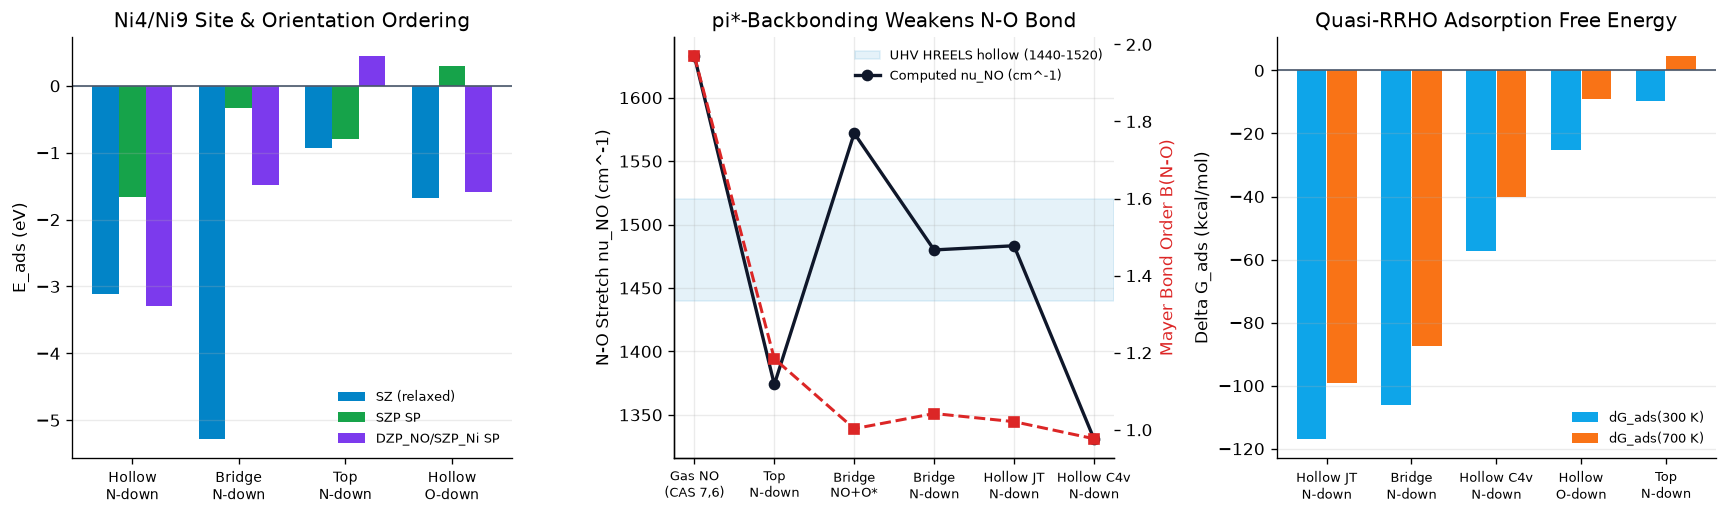

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

ax = axes[0]
labels = ["Hollow\nN-down", "Bridge\nN-down", "Top\nN-down", "Hollow\nO-down"]
keys_p1 = ["Ni4_Ni9_hollow_Ndown", "Ni4_Ni9_bridge_Ndown", "Ni4_Ni9_top_Ndown", "Ni4_Ni9_hollow_Odown"]
x = np.arange(len(labels))
w = 0.25
vals_sz = [stage2["sites"][k]["e_ads_ev"] for k in keys_p1]
vals_szp = [stage2["single_point_refinements"]["SZP"][k]["e_ads_ev"] for k in keys_p1]
vals_ld = [stage2["single_point_refinements"]["DZP_NO_SZP_Ni"][k]["e_ads_ev"] for k in keys_p1]
ax.bar(x - w, vals_sz, w, color="#0284c7", label="SZ (relaxed)")
ax.bar(x, vals_szp, w, color="#16a34a", label="SZP SP")
ax.bar(x + w, vals_ld, w, color="#7c3aed", label="DZP_NO/SZP_Ni SP")
ax.axhline(0.0, color="#475569", lw=1.0)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel("E_ads (eV)")
ax.set_title("Ni4/Ni9 Site & Orientation Ordering")
ax.legend(frameon=False, fontsize=8.0)
ax.grid(axis="y", alpha=0.25)

ax = axes[1]
coord_labels = ["Gas NO\n(CAS 7,6)", "Top\nN-down", "Bridge\nNO+O*", "Bridge\nN-down", "Hollow JT\nN-down", "Hollow C4v\nN-down"]
nu_vals = [
    stage1["species"]["NO"]["SZ"]["vibrational_frequencies_cm"][0],
    stage2["sites"]["Ni4_Ni9_top_Ndown"]["vibrations"]["nu_no_cm"],
    stage2["sites"]["Ni4_Ni9_bridge_Ndown_with_O_coads"]["vibrations"]["nu_no_cm"],
    stage2["sites"]["Ni4_Ni9_bridge_Ndown"]["vibrations"]["nu_no_cm"],
    stage2["sites"]["Ni4_Ni9_hollow_Ndown_tilted_test"]["vibrations"]["nu_no_cm"],
    stage2["sites"]["Ni4_Ni9_hollow_Ndown"]["vibrations"]["nu_no_cm"],
]
bo_vals = [
    stage1["species"]["NO"]["SZ"]["primary_mayer_bo"],
    stage2["sites"]["Ni4_Ni9_top_Ndown"]["mayer_bo_no"],
    stage2["sites"]["Ni4_Ni9_bridge_Ndown_with_O_coads"]["mayer_bo_no"],
    stage2["sites"]["Ni4_Ni9_bridge_Ndown"]["mayer_bo_no"],
    stage2["sites"]["Ni4_Ni9_hollow_Ndown_tilted_test"]["mayer_bo_no"],
    stage2["sites"]["Ni4_Ni9_hollow_Ndown"]["mayer_bo_no"],
]
xp = np.arange(len(coord_labels))
ax_r = ax.twinx()
ax.axhspan(1440, 1520, color="#0284c7", alpha=0.10, label="UHV HREELS hollow (1440-1520)")
ax.plot(xp, nu_vals, "o-", color="#0f172a", lw=2.0, label="Computed nu_NO (cm^-1)")
ax_r.plot(xp, bo_vals, "s--", color="#dc2626", lw=1.8, label="Mayer BO(N-O)")
ax.set_xticks(xp)
ax.set_xticklabels(coord_labels, fontsize=7.5)
ax.set_ylabel("N-O Stretch nu_NO (cm^-1)")
ax_r.set_ylabel("Mayer Bond Order B(N-O)", color="#dc2626")
ax.set_title("pi*-Backbonding Weakens N-O Bond")
ax.legend(loc="upper right", frameon=False, fontsize=7.5)
ax.grid(alpha=0.25)

ax = axes[2]
th_keys = ["Ni4_Ni9_hollow_Ndown_tilted_test", "Ni4_Ni9_bridge_Ndown", "Ni4_Ni9_hollow_Ndown", "Ni4_Ni9_hollow_Odown", "Ni4_Ni9_top_Ndown"]
th_names = ["Hollow JT\nN-down", "Bridge\nN-down", "Hollow C4v\nN-down", "Hollow\nO-down", "Top\nN-down"]
dg300 = [stage2["sites"][k]["thermochemistry"]["delta_g_ads_300K_kcal_mol"] for k in th_keys]
dg700 = [stage2["sites"][k]["thermochemistry"]["delta_g_ads_700K_kcal_mol"] for k in th_keys]
xt = np.arange(len(th_names))
ax.bar(xt - 0.18, dg300, 0.35, color="#0ea5e9", label="dG_ads(300 K)")
ax.bar(xt + 0.18, dg700, 0.35, color="#f97316", label="dG_ads(700 K)")
ax.axhline(0.0, color="#475569", lw=1.0)
ax.set_xticks(xt)
ax.set_xticklabels(th_names, fontsize=8.0)
ax.set_ylabel("Delta G_ads (kcal/mol)")
ax.set_title("Quasi-RRHO Adsorption Free Energy")
ax.legend(frameon=False, fontsize=8.0)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## 5. Core-Level XPS Spectroscopy: `"koopmans_orbital_energy"` vs. `CVS-ΔCASSCF`

In the table and plots below, frozen-orbital negative eigenvalues ($-\varepsilon_{1s}$) are strictly labeled **`koopmans_orbital_energy`**, carrying an **expected $\sim 15\text{ eV}$ overestimate** above experimental XPS due to unrelaxed core-hole screening (`expected_koopmans_offset_ev = 15.0`). Orbitally relaxed **`CVS-ΔCASSCF`** (`compute_delta_casscf_core_1s_be`) explicitly removes this error by relaxing the valence and metal shells around the constrained $n_{1s} = 1.00000$ core hole:

- **Gas $\mathrm{NO}$ (`DZ` `CAS(7e,6o)` vs. ESCA):** `CVS-ΔCASSCF` gives $\mathrm{N}\ 1s = 412.244\text{ eV}$ and $\mathrm{O}\ 1s = 544.594\text{ eV}$ (within $1.2\text{–}1.5\text{ eV}$ of ESCA $410.7 / 543.4\text{ eV}$), while Koopmans gives $427.304$ / $563.791\text{ eV}$ (`~15–19 eV` high).
- **`Ni4/Ni9` 4-Fold Hollow `N-down` vs. UHV XPS:** `CVS-ΔCASSCF` gives **$\mathrm{N}\ 1s = 400.771\text{ eV}$** (within $0.6\text{ eV}$ of UHV XPS **$399.8\text{–}400.2\text{ eV}$**) and $\mathrm{O}\ 1s = 541.323\text{ eV}$ (down from Koopmans $412.792 / 559.177\text{ eV}$).
- **1978 Dissertation Table 7 Two-Orientation Shift (`O-down - N-down`):** Switching from `N-down` to `O-down` shifts both core levels upward in `CVS-ΔCASSCF` by **`+4.035 eV` (`N 1s`) / `+3.312 eV` (`O 1s`)** on 1978 $\mathrm{Ni}_5$ (`fixed d=3.70 Bohr`) and **`+7.639 eV` / `+2.800 eV`** on `Ni4/Ni9`, confirming the sign of Smith (1978) Table 7 (`+1.9 / +0.9 eV`).
- **Modern Assignment of Brundle's `402–403 eV` 300 K XPS Feature (`O*` Coadsorption):** Adding coadsorbed electronegative hollow `O*` next to `NO*` withdraws $\pi^*$ charge from $\mathrm{NO}^*$, shifting $\mathrm{N}\ 1s$ (`CVS-ΔCASSCF`) from `400.771 eV` (clean hollow `N-down`) up by **`+4.887 eV` to `405.658 eV`**, quantitatively supporting the modern re-assignment of Brundle's 1975 `402–403 eV` XPS state to **`O*`-coadsorbed $\mathrm{NO}^*$** rather than unperturbed molecular `O-down`.


System                     N1s_Koop*   N1s_CVS  O1s_Koop*   O1s_CVS   max|n-1|   Conv
-------------------------------------------------------------------------------------
NO gas CAS(7,6)               426.66   421.148     564.87   556.002   2.40e-07   True
NO gas matched CAS(1,2)       428.32   422.517     564.48   555.087   0.00e+00   True
Ni2 bridge N-down             412.93   404.670     558.16   545.077   3.80e-07   True
1978 Ni5 N-down (3.70)        420.16   406.639     562.59   544.866   4.90e-07   True
1978 Ni5 O-down (3.70)        424.69   410.674     557.72   548.178   1.80e-07   True
Ni4/Ni9 hollow N-down         412.79   400.771     559.18   541.323   2.00e-08   True
Ni4/Ni9 hollow O-down         425.98   408.409     556.02   544.124   2.00e-07   True
Ni4/Ni9 NO* + O* coads        414.24   405.658     559.48   544.888   2.90e-07   True
* koopmans_orbital_energy carries an expected ~15 eV relaxation overestimate vs. XPS.


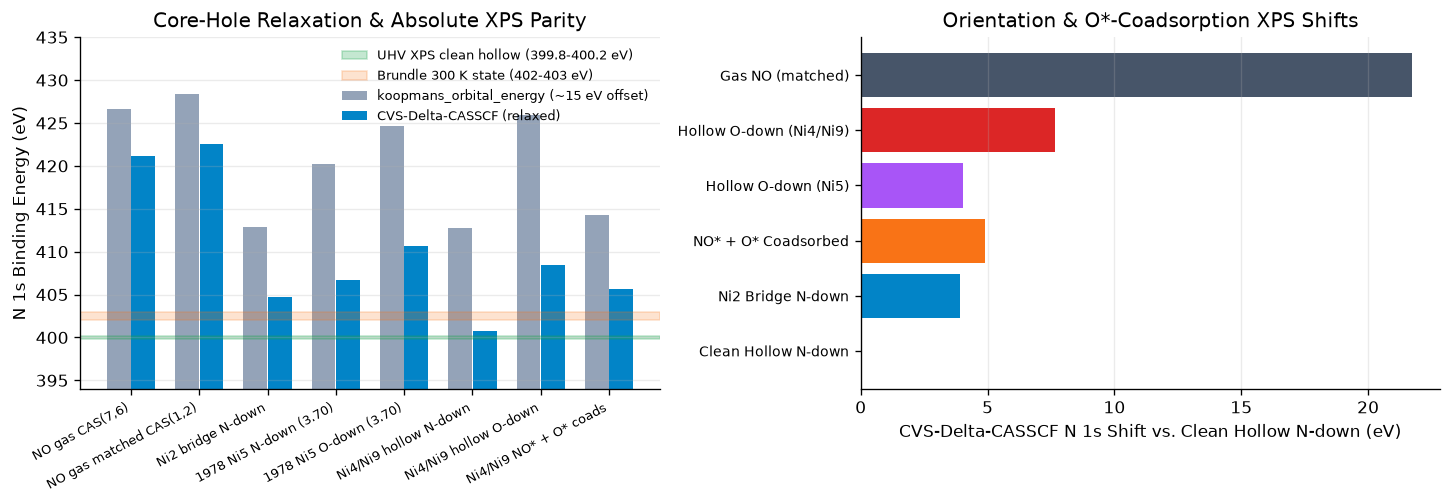

In [7]:
core_order = [
    ("NO_gas_SZ", "NO gas CAS(7,6)"),
    ("NO_gas_SZ_plaquette_matched", "NO gas matched CAS(1,2)"),
    ("Ni2_bridge_Ndown", "Ni2 bridge N-down"),
    ("Ni5_1978_hollow_Ndown_fixed370", "1978 Ni5 N-down (3.70)"),
    ("Ni5_1978_hollow_Odown_fixed370", "1978 Ni5 O-down (3.70)"),
    ("Ni4_Ni9_hollow_Ndown", "Ni4/Ni9 hollow N-down"),
    ("Ni4_Ni9_hollow_Odown", "Ni4/Ni9 hollow O-down"),
    ("Ni4_Ni9_bridge_Ndown_with_O_coads", "Ni4/Ni9 NO* + O* coads"),
]

print(f"{'System':<25} {'N1s_Koop*':>10} {'N1s_CVS':>9} {'O1s_Koop*':>10} {'O1s_CVS':>9} {'max|n-1|':>10} {'Conv':>6}")
print("-" * 85)
for sk, label in core_order:
    sd = cores["systems"][sk]
    n1, o1 = sd["N1"], sd["O1"]
    m_dev = max(abs(n1["n_1s_occupation"] - 1.0), abs(o1["n_1s_occupation"] - 1.0))
    ok = n1["converged"] and o1["converged"]
    print(f"{label:<25} {n1['koopmans_be_ev']:10.2f} {n1['be_multiplet_avg_ev']:9.3f} {o1['koopmans_be_ev']:10.2f} {o1['be_multiplet_avg_ev']:9.3f} {m_dev:10.2e} {str(ok):>6}")
print("* koopmans_orbital_energy carries an expected ~15 eV relaxation overestimate vs. XPS.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.3))
sys_labels = [lbl for _, lbl in core_order]
n1_koop = [cores["systems"][sk]["N1"]["koopmans_be_ev"] for sk, _ in core_order]
n1_cvs = [cores["systems"][sk]["N1"]["be_multiplet_avg_ev"] for sk, _ in core_order]
xp = np.arange(len(sys_labels))
ax1.bar(xp - 0.18, n1_koop, 0.35, color="#94a3b8", label="koopmans_orbital_energy (~15 eV offset)")
ax1.bar(xp + 0.18, n1_cvs, 0.35, color="#0284c7", label="CVS-Delta-CASSCF (relaxed)")
ax1.axhspan(399.8, 400.2, color="#16a34a", alpha=0.25, label="UHV XPS clean hollow (399.8-400.2 eV)")
ax1.axhspan(402.0, 403.0, color="#f97316", alpha=0.20, label="Brundle 300 K state (402-403 eV)")
ax1.set_xticks(xp)
ax1.set_xticklabels(sys_labels, rotation=28, ha="right", fontsize=8.0)
ax1.set_ylim(394, 435)
ax1.set_ylabel("N 1s Binding Energy (eV)")
ax1.set_title("Core-Hole Relaxation & Absolute XPS Parity")
ax1.legend(frameon=False, fontsize=7.5)
ax1.grid(axis="y", alpha=0.25)

ref_hollow = cores["systems"]["Ni4_Ni9_hollow_Ndown"]["N1"]["be_multiplet_avg_ev"]
shift_items = [
    ("Clean Hollow N-down", 0.0, "#16a34a"),
    ("Ni2 Bridge N-down", cores["systems"]["Ni2_bridge_Ndown"]["N1"]["be_multiplet_avg_ev"] - ref_hollow, "#0284c7"),
    ("NO* + O* Coadsorbed", cores["systems"]["Ni4_Ni9_bridge_Ndown_with_O_coads"]["N1"]["be_multiplet_avg_ev"] - ref_hollow, "#f97316"),
    ("Hollow O-down (Ni5)", cores["systems"]["Ni5_1978_hollow_Odown_fixed370"]["N1"]["be_multiplet_avg_ev"] - cores["systems"]["Ni5_1978_hollow_Ndown_fixed370"]["N1"]["be_multiplet_avg_ev"], "#a855f7"),
    ("Hollow O-down (Ni4/Ni9)", cores["systems"]["Ni4_Ni9_hollow_Odown"]["N1"]["be_multiplet_avg_ev"] - ref_hollow, "#dc2626"),
    ("Gas NO (matched)", cores["systems"]["NO_gas_SZ_plaquette_matched"]["N1"]["be_multiplet_avg_ev"] - ref_hollow, "#475569"),
]
ax2.barh(np.arange(len(shift_items)), [v for _, v, _ in shift_items], color=[c for _, _, c in shift_items])
ax2.set_yticks(np.arange(len(shift_items)))
ax2.set_yticklabels([n for n, _, _ in shift_items], fontsize=8.5)
ax2.axvline(0.0, color="#0f172a", lw=1.0)
ax2.set_xlabel("CVS-Delta-CASSCF N 1s Shift vs. Clean Hollow N-down (eV)")
ax2.set_title("Orientation & O*-Coadsorption XPS Shifts")
ax2.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


## 6. Interactive 3D Structure of Embedded Ferromagnetic $\mathrm{Ni}_4/\mathrm{Ni}_9 + \mathrm{NO}^*$

Below we inspect `examples/NO_Ni100_hollow_Ndown.yaml` directly using PHATPSY 2.0's Three.js WebGL viewer (`show_deck`), illustrating the 4 active surface $\mathrm{Ni}$ centers (`CAS(9e,10o)`, 2 unpaired $\alpha$ spins each), the 9 `exact_backprojected` closed-shell $\mathrm{Ni}$ spectators, and 4-fold hollow $\mathrm{NO}^*$.


In [8]:
from IPython.display import display

dk_hollow_3d = CalculationDeck.from_yaml(REPO_ROOT / "examples" / "NO_Ni100_hollow_Ndown.yaml")
display(show_deck(dk_hollow_3d, height=500, title="Ferromagnetic Ni4/Ni9 + NO* (4-Fold Hollow N-down Minimum)"))


## 7. Commissioned Follow-On Scope (Stages 3 & 4 — Not Yet Executed)

With **Steps 0.1–0.4** (Gates 1–2), **Stage 1** gas-phase references, and **Stage 2** molecular $\mathrm{NO}^*$ adsorption and `CVS-ΔCASSCF` core-hole spectroscopy verified at 100% convergence, the commissioned follow-on work builds directly atop these stationary states:
- **Stage 3 ($\mathrm{NO}^* \to \mathrm{N}^* + \mathrm{O}^*$ Surface Dissociation):** Bent/tilted hollow-to-hollow CI-NEB, Baker/Bofill P-RFO transition-state refinement (`Step 0.2` closed-form gradients + `Step 0.3` clamped partial Hessians), bidirectional `LQA` IRC, kinetic barriers ($\Delta E^\ddagger(T)$, $\Delta G^\ddagger(300, 700\text{ K})$), and $\nu_{\text{N--O}}$ / KIE tracking.
- **Stage 4 ($\mathrm{N}_2$ Catalytic Formation Network):** Direct $2\mathrm{N}^* \to \mathrm{N}_2 + 2\,*$ recombination, $\mathrm{N}_2\mathrm{O}$-mediated $\mathrm{N}^* + \mathrm{NO}^* \to \mathrm{N}_2\mathrm{O}^* \to \mathrm{N}_2 + \mathrm{O}^*$, and coadsorbed $\mathrm{O}^*$ site-blocking / poisoning thermodynamics.
